# AskAuto — Architecture

Visual companion to `docs/ARCHITECTURE.md`.

> **Note on source of truth.** The markdown files in `docs/` are what Claude Code reads. This notebook is for humans — presenting, reviewing, and teaching. If the two ever disagree, the markdown wins.

Run all cells to render the diagrams, or read the saved outputs as-is.

In [1]:
from IPython.display import SVG, display

STYLE = """<style>
  .bx  { fill:#f6f8fa; stroke:#d0d7de; stroke-width:1; }
  .bxa { fill:#f3f0ff; stroke:#8b7fd4; stroke-width:1; }
  .bxw { fill:#fff8e6; stroke:#d4a72c; stroke-width:1; }
  .th  { font:600 13px -apple-system,Segoe UI,Helvetica,sans-serif; fill:#1f2328; }
  .ts  { font:400 11px -apple-system,Segoe UI,Helvetica,sans-serif; fill:#656d76; }
  .tl  { font:600 11px -apple-system,Segoe UI,Helvetica,sans-serif; fill:#8250df;
         letter-spacing:.06em; }
  .arr { stroke:#656d76; stroke-width:1.4; fill:none; }
  .arrR{ stroke:#d1242f; stroke-width:1.6; fill:none; stroke-dasharray:5 3; }
  .lbl { font:400 10px -apple-system,Segoe UI,Helvetica,sans-serif; fill:#d1242f; }
</style>
<defs>
  <marker id="a" viewBox="0 0 10 10" refX="8" refY="5" markerWidth="6"
          markerHeight="6" orient="auto-start-reverse">
    <path d="M2 1L8 5L2 9" fill="none" stroke="#656d76" stroke-width="1.5"
          stroke-linecap="round" stroke-linejoin="round"/>
  </marker>
  <marker id="ar" viewBox="0 0 10 10" refX="8" refY="5" markerWidth="6"
          markerHeight="6" orient="auto-start-reverse">
    <path d="M2 1L8 5L2 9" fill="none" stroke="#d1242f" stroke-width="1.5"
          stroke-linecap="round" stroke-linejoin="round"/>
  </marker>
</defs>"""

def diagram(body, width=720, height=400):
    """Render a self-contained SVG diagram inline."""
    return SVG(f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" '
               f'height="{height}" viewBox="0 0 {width} {height}">'
               f'{STYLE}{body}</svg>')


## 1. Two phases, two rules about database access

The most common confusion in this design is *who is allowed to open the database*. The answer depends on which phase you are in.

**Build time** runs once, on a developer machine, before the server exists. Scripts open SQLite directly, and that is correct — the same way database migrations bypass the application layer.

**Runtime** serves requests. Here the MCP server is the only process permitted to touch the database. FastAPI and the agent reach data exclusively through it.

So the *only MCP touches the database* invariant governs the request path, not the tooling.

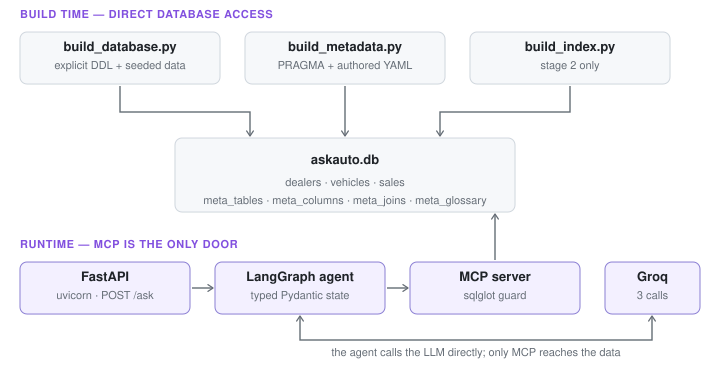

In [2]:
diagram("""
<text class="tl" x="20" y="18">BUILD TIME — DIRECT DATABASE ACCESS</text>
<rect x="20" y="32" width="200" height="52" rx="7" class="bx"/><text class="th" x="120.0" y="51.0" text-anchor="middle">build_database.py</text><text class="ts" x="120.0" y="69.0" text-anchor="middle">explicit DDL + seeded data</text>
<rect x="245" y="32" width="200" height="52" rx="7" class="bx"/><text class="th" x="345.0" y="51.0" text-anchor="middle">build_metadata.py</text><text class="ts" x="345.0" y="69.0" text-anchor="middle">PRAGMA + authored YAML</text>
<rect x="470" y="32" width="200" height="52" rx="7" class="bx"/><text class="th" x="570.0" y="51.0" text-anchor="middle">build_index.py</text><text class="ts" x="570.0" y="69.0" text-anchor="middle">stage 2 only</text>
<path d="M120 86 L120 112 L250 112 L250 136" class="arr" marker-end="url(#a)"/>
<line x1="345" y1="86" x2="345" y2="136" class="arr" marker-end="url(#a)"/>
<path d="M570 86 L570 112 L440 112 L440 136" class="arr" marker-end="url(#a)"/>

<rect x="175" y="138" width="340" height="74" rx="7" class="bx"/>
<text class="th" x="345" y="164" text-anchor="middle">askauto.db</text>
<text class="ts" x="345" y="186" text-anchor="middle">dealers · vehicles · sales</text>
<text class="ts" x="345" y="204" text-anchor="middle">meta_tables · meta_columns · meta_joins · meta_glossary</text>

<text class="tl" x="20" y="248">RUNTIME — MCP IS THE ONLY DOOR</text>
<rect x="20" y="262" width="170" height="52" rx="7" class="bxa"/><text class="th" x="105.0" y="281.0" text-anchor="middle">FastAPI</text><text class="ts" x="105.0" y="299.0" text-anchor="middle">uvicorn · POST /ask</text>
<rect x="215" y="262" width="170" height="52" rx="7" class="bxa"/><text class="th" x="300.0" y="281.0" text-anchor="middle">LangGraph agent</text><text class="ts" x="300.0" y="299.0" text-anchor="middle">typed Pydantic state</text>
<rect x="410" y="262" width="170" height="52" rx="7" class="bxa"/><text class="th" x="495.0" y="281.0" text-anchor="middle">MCP server</text><text class="ts" x="495.0" y="299.0" text-anchor="middle">sqlglot guard</text>
<rect x="605" y="262" width="95" height="52" rx="7" class="bxa"/><text class="th" x="652.5" y="281.0" text-anchor="middle">Groq</text><text class="ts" x="652.5" y="299.0" text-anchor="middle">3 calls</text>
<line x1="192" y1="288" x2="213" y2="288" class="arr" marker-end="url(#a)"/>
<line x1="387" y1="288" x2="408" y2="288" class="arr" marker-end="url(#a)"/>
<path d="M300 316 L300 340 L652 340 L652 316" class="arr" marker-start="url(#a)"
      marker-end="url(#a)"/>
<line x1="495" y1="260" x2="495" y2="214" class="arr" marker-end="url(#a)"/>
<text class="ts" x="476" y="356" text-anchor="middle">the agent calls the LLM directly; only MCP reaches the data</text>
""", width=720, height=372)

### Why the boundary is worth the effort

A plain Python function would also read the database. Four reasons to put a protocol there instead, in order of how much they matter:

1. **The guard cannot be bypassed.** SQL validation lives inside `run_sql`. Whatever the model generates, however creatively, goes through that check. A prompt instruction saying *only write SELECT* is a suggestion; a server-side AST check is a rule.
2. **The data layer is testable with no agent.** Open MCP Inspector, click the tools, read the output. Finding a bug there takes thirty seconds instead of debugging five graph nodes.
3. **Swapping SQLite for Athena touches one file** the agent never sees.
4. **Other clients get it free.** Point Claude Desktop at the same server and explore the data by hand.

## 2. Module boundaries

Each module has a short list of things it may import and a shorter list of things it must not. These are deliberately checkable by grep, which is what makes them enforceable rather than aspirational.

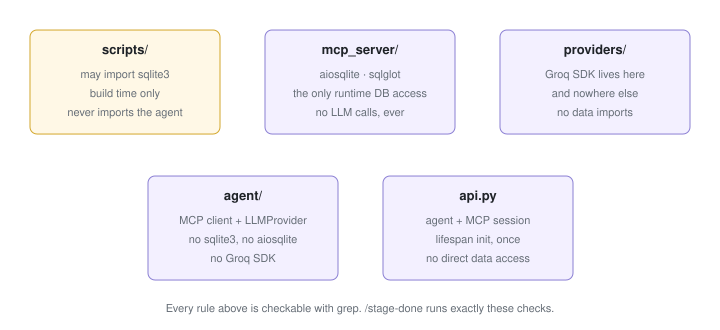

In [3]:
diagram("""
<rect x="30" y="30" width="190" height="104" rx="7" class="bxw"/><text class="th" x="125.0" y="54" text-anchor="middle">scripts/</text><text class="ts" x="125.0" y="78" text-anchor="middle">may import sqlite3</text><text class="ts" x="125.0" y="97" text-anchor="middle">build time only</text><text class="ts" x="125.0" y="116" text-anchor="middle">never imports the agent</text>
<rect x="265" y="30" width="190" height="104" rx="7" class="bxa"/><text class="th" x="360.0" y="54" text-anchor="middle">mcp_server/</text><text class="ts" x="360.0" y="78" text-anchor="middle">aiosqlite · sqlglot</text><text class="ts" x="360.0" y="97" text-anchor="middle">the only runtime DB access</text><text class="ts" x="360.0" y="116" text-anchor="middle">no LLM calls, ever</text>
<rect x="500" y="30" width="190" height="104" rx="7" class="bxa"/><text class="th" x="595.0" y="54" text-anchor="middle">providers/</text><text class="ts" x="595.0" y="78" text-anchor="middle">Groq SDK lives here</text><text class="ts" x="595.0" y="97" text-anchor="middle">and nowhere else</text><text class="ts" x="595.0" y="116" text-anchor="middle">no data imports</text>
<rect x="148" y="176" width="190" height="104" rx="7" class="bxa"/><text class="th" x="243.0" y="200" text-anchor="middle">agent/</text><text class="ts" x="243.0" y="224" text-anchor="middle">MCP client + LLMProvider</text><text class="ts" x="243.0" y="243" text-anchor="middle">no sqlite3, no aiosqlite</text><text class="ts" x="243.0" y="262" text-anchor="middle">no Groq SDK</text>
<rect x="383" y="176" width="190" height="104" rx="7" class="bxa"/><text class="th" x="478.0" y="200" text-anchor="middle">api.py</text><text class="ts" x="478.0" y="224" text-anchor="middle">agent + MCP session</text><text class="ts" x="478.0" y="243" text-anchor="middle">lifespan init, once</text><text class="ts" x="478.0" y="262" text-anchor="middle">no direct data access</text>
<text class="ts" x="360" y="312" text-anchor="middle">Every rule above is checkable with grep. /stage-done runs exactly these checks.</text>
""", width=720, height=330)

The `providers/` boundary is easy to overlook and worth holding. Keeping the Groq SDK in exactly one place is what makes the Bedrock swap a configuration change later. The moment a second module imports it directly, that promise quietly stops being true.

## 3. The agent graph

State is a single Pydantic model. Nodes take state and return state.

The dashed red edges are the important part. Three edges go backwards, and they are the entire justification for using LangGraph rather than three `await` statements in a row. Remove them and you should delete the dependency.

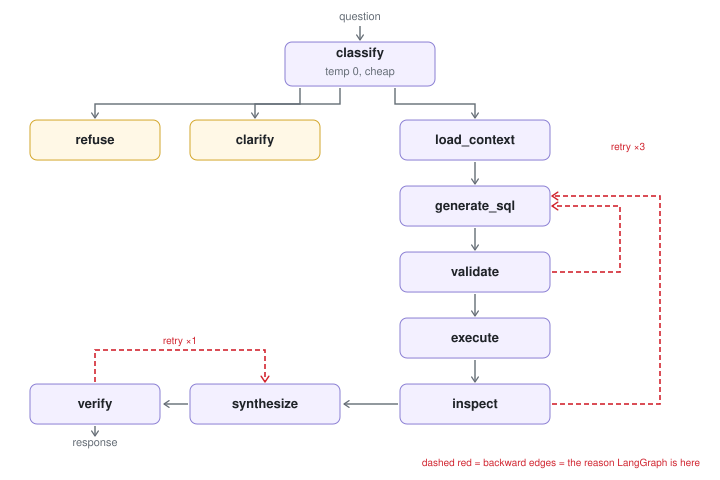

In [4]:
diagram("""
<text class="ts" x="360" y="20" text-anchor="middle">question</text>
<line x1="360" y1="26" x2="360" y2="40" class="arr" marker-end="url(#a)"/>
<rect x="285" y="42" width="150" height="44" rx="7" class="bxa"/><text class="th" x="360.0" y="57.0" text-anchor="middle">classify</text><text class="ts" x="360.0" y="75.0" text-anchor="middle">temp 0, cheap</text>

<rect x="30" y="120" width="130" height="40" rx="7" class="bxw"/><text class="th" x="95.0" y="144.0" text-anchor="middle">refuse</text>
<rect x="190" y="120" width="130" height="40" rx="7" class="bxw"/><text class="th" x="255.0" y="144.0" text-anchor="middle">clarify</text>
<path d="M300 88 L300 104 L95 104 L95 118" class="arr" marker-end="url(#a)"/>
<path d="M340 88 L340 104 L255 104 L255 118" class="arr" marker-end="url(#a)"/>

<rect x="400" y="120" width="150" height="40" rx="7" class="bxa"/><text class="th" x="475.0" y="144.0" text-anchor="middle">load_context</text>
<path d="M395 88 L395 104 L475 104 L475 118" class="arr" marker-end="url(#a)"/>

<rect x="400" y="186" width="150" height="40" rx="7" class="bxa"/><text class="th" x="475.0" y="210.0" text-anchor="middle">generate_sql</text>
<line x1="475" y1="162" x2="475" y2="184" class="arr" marker-end="url(#a)"/>
<rect x="400" y="252" width="150" height="40" rx="7" class="bxa"/><text class="th" x="475.0" y="276.0" text-anchor="middle">validate</text>
<line x1="475" y1="228" x2="475" y2="250" class="arr" marker-end="url(#a)"/>
<rect x="400" y="318" width="150" height="40" rx="7" class="bxa"/><text class="th" x="475.0" y="342.0" text-anchor="middle">execute</text>
<line x1="475" y1="294" x2="475" y2="316" class="arr" marker-end="url(#a)"/>
<rect x="400" y="384" width="150" height="40" rx="7" class="bxa"/><text class="th" x="475.0" y="408.0" text-anchor="middle">inspect</text>
<line x1="475" y1="360" x2="475" y2="382" class="arr" marker-end="url(#a)"/>

<path d="M600 272 L620 272 L620 206 L552 206" class="arrR" marker-end="url(#ar)"/>
<line x1="552" y1="272" x2="598" y2="272" class="arrR"/>
<path d="M600 404 L660 404 L660 196 L552 196" class="arrR" marker-end="url(#ar)"/>
<line x1="552" y1="404" x2="598" y2="404" class="arrR"/>
<text class="lbl" x="628" y="150" text-anchor="middle">retry ×3</text>

<rect x="190" y="384" width="150" height="40" rx="7" class="bxa"/><text class="th" x="265.0" y="408.0" text-anchor="middle">synthesize</text>
<line x1="398" y1="404" x2="344" y2="404" class="arr" marker-end="url(#a)"/>
<rect x="30" y="384" width="130" height="40" rx="7" class="bxa"/><text class="th" x="95.0" y="408.0" text-anchor="middle">verify</text>
<line x1="188" y1="404" x2="164" y2="404" class="arr" marker-end="url(#a)"/>
<path d="M95 382 L95 350 L265 350 L265 382" class="arrR" marker-end="url(#ar)"/>
<text class="lbl" x="180" y="344" text-anchor="middle">retry ×1</text>

<text class="ts" x="95" y="446" text-anchor="middle">response</text>
<line x1="95" y1="426" x2="95" y2="436" class="arr" marker-end="url(#a)"/>

<text class="lbl" x="700" y="466" text-anchor="end">dashed red = backward edges = the reason LangGraph is here</text>
""", width=720, height=480)

### Node responsibilities

| Node | LLM? | MCP? | Notes |
|---|---|---|---|
| `classify` | yes, temp 0 | no | uses the known-unanswerable list |
| `load_context` | no | yes | cached after the first call |
| `generate_sql` | yes, temp 0 | no | returns a typed `SQLPlan` |
| `validate` | no | no | sqlglot on the AST |
| `execute` | no | yes | `run_sql` |
| `inspect` | no | no | three-way branch |
| `synthesize` | yes, ~0.4 | no | prose |
| `verify` | no | no | numeric containment check |

Two ordering decisions worth naming:

**`classify` runs before `load_context`.** An unanswerable question costs one cheap LLM call and never touches the database. Order it the other way and you do retrieval work for questions you were always going to refuse.

**Retry ceilings live in the edge functions, not the nodes.** A node should not know how many times it has been called. That is the graph's business.

## 4. Where async helps, and where it doesn't

Worth being precise about, because it is easy to oversell.

**Does not help single-request latency.** `generate_sql` and `synthesize` are inherently sequential — you cannot write the answer before you have the rows.

**Does help** with serving concurrent requests without blocking, keeping the event loop free during network waits, and streaming tokens to the client.

Three LLM calls, two MCP calls, under 8 seconds at p95. Claiming async makes one question faster invites a question you cannot answer.

## 5. Stage boundaries

| Stage | Change | Touches |
|---|---|---|
| 1 | Working agent, `SCHEMA_MODE=full` | everything |
| 2 | Vector schema retrieval | `mcp_server/` only, plus a config flag |
| 3 | SQL example retrieval | `mcp_server/` only |
| 4 | Free-text column, supervisor + specialists | `agent/` graph shape |

**Stage 2 touching only one module is the test of whether stage 1 got the boundaries right.** If enabling vector retrieval requires agent changes, the abstraction leaked and it is worth going back to find out where.

This is why `get_schema_context(question)` accepts a question from day one even though stage 1 ignores it.